# Demo Klik + Diagnostik Turbo vs Fine-tuned (CMRxMotion)

Dua hal dalam satu notebook:

Demo klik interaktif (short-axis) dengan **pemilih model di UI** — Turbo (zero-shot) atau
Fine-tuned. Untuk bimbingan, pakai Turbo supaya mulus; bisa juga diganti ke Fine-tuned
on-the-fly untuk menunjukkan bedanya langsung.

Sel diagnostik yang menjalankan klik oracle untuk KEDUA model berdampingan pada kasus
yang sama, menampilkan kurva DSC-vs-klik dan mask akhir side-by-side. Ini bukti konkret
"zero-shot vs fine-tuned" untuk dibawa ke dosbing.

Catatan: Turbo bisa MYO juga (zero-shot = tanpa pelatihan olehmu; turbo model umum yang
bisa di-prompt struktur apa pun). Yang "cuma LV/RV" itu checkpoint fine-tune-mu.

## Langkah 0 — Prasyarat & struktur folder

**Software:** Python 3.10+, dan paket: `torch` (versi CUDA), `nibabel`, `numpy`, `pandas`, `scipy`, `matplotlib`, `ipywidgets`, `ipympl`.
> `ipympl` wajib supaya `%matplotlib widget` (kanvas klik interaktif) muncul. Tanpa ini, UI tidak akan tampil.

```
D:\Joel\
├─ Dataset\
│  └─ data\                         # citra + mask .nii.gz (CMRxMotion)
│       ├─ P001.nii.gz              # citra
│       ├─ P001-mask.nii.gz         # label/GT (nama mengandung mask/label/seg/gt)
│       └─ ...
├─ work\
│  ├─ sam_ft_frozen\
│  │   ├─ fold0\sam_model_best.pth  # checkpoint fine-tuned (frozen, best-val) per fold
│  │   ├─ fold1\sam_model_best.pth
│  │   └─ ... fold4
│  └─ results_noc\
│       └─ folds_subjek.csv          # pembagian subjek per fold (kolom: stem, fold)
└─ SAM-Med3D\                        # repo SAM-Med3D hasil clone
   └─ ckpt\sam_med3d_turbo.pth       # checkpoint Turbo (zero-shot)
```

**Menyiapkan repo + checkpoint Turbo**
```
git clone https://github.com/uni-medical/SAM-Med3D.git D:\Joel\SAM-Med3D
# unduh sam_med3d_turbo.pth dari rilis resmi SAM-Med3D, taruh di D:\Joel\SAM-Med3D\ckpt\
```
Checkpoint `sam_ft_frozen\fold*\sam_model_best.pth` -> hasil training

## 1. Konfigurasi + data

In [1]:
%matplotlib widget
from pathlib import Path
import os, re, glob, sys
import numpy as np, pandas as pd, nibabel as nib
import matplotlib.pyplot as plt
import ipywidgets as W
from IPython.display import display
from scipy import ndimage

DATASET_PATH=Path(r"D:\Joel\Dataset"); DATA_DIR=DATASET_PATH/"data"
WORK_DIR=Path(r"D:\Joel\work"); RESULT_DIR=WORK_DIR/"results_noc"
SAM_REPO=Path(r"D:\Joel\SAM-Med3D")
CKPT_ZEROSHOT=SAM_REPO/"ckpt"/"sam_med3d_turbo.pth"
ckpt_fold=lambda f: WORK_DIR/"sam_ft_frozen"/f"fold{f}"/"sam_model_best.pth"

SAM_SPACING=(1.5,1.5,1.5); SAM_ROI=128; MAX_CLICKS=15
CLASS_NAMES={1:"LV",2:"MYO",3:"RV"}; FOCUS={1:"LV",2:"MYO",3:"RV"}  # turbo bisa ketiganya
VIEW_AXIS=None   # None=auto short-axis (axis spacing terbesar); 0/1/2 manual

folds=pd.read_csv(RESULT_DIR/"folds_subjek.csv")
def stem_of(p):
    s=os.path.basename(p).replace(".nii.gz","").replace(".nii","")
    return re.sub(r"[-_](mask|label|seg|gt)$","",s,flags=re.IGNORECASE)
allf=sorted(glob.glob(str(DATA_DIR/"**"/"*.nii.gz"),recursive=True))
is_mask=lambda p: any(k in os.path.basename(p).lower() for k in ("mask","label","-seg","_gt"))
img_by={stem_of(p):p for p in allf if not is_mask(p)}; msk_by={stem_of(p):p for p in allf if is_mask(p)}
df=folds.copy(); df["image"]=df.stem.map(img_by); df["label"]=df.stem.map(msk_by)
fold_of=dict(zip(df.stem,df.fold))
print("kasus:",len(df))

kasus: 138


## 2. Preprocessing, metrik, oracle klik

In [2]:
def load_vol(p):
    a=nib.load(p).get_fdata(); return a[...,0] if a.ndim==4 else a
def native_spacing(p): return tuple(float(z) for z in nib.load(p).header.get_zooms()[:3])
def resample_iso(v,sp,is_label=False):
    f=tuple(float(s)/float(d) for s,d in zip(sp,SAM_SPACING)); return ndimage.zoom(v,f,order=0 if is_label else 1)
def crop_center(v,c,size=SAM_ROI):
    h=size//2; st=[int(round(x))-h for x in c]; out=np.zeros((size,)*3,v.dtype); s_,d_=[],[]
    for ax in range(3):
        a=max(0,st[ax]); b=min(v.shape[ax],st[ax]+size); s_.append(slice(a,b)); d_.append(slice(a-st[ax],a-st[ax]+(b-a)))
    out[tuple(d_)]=v[tuple(s_)]; return out
def znorm(roi): return (roi-float(roi.mean()))/(float(roi.std())+1e-6)
def dsc(p,r):
    p,r=p>0,r>0; d=p.sum()+r.sum(); return 0.0 if d==0 else float(2*(p&r).sum()/d)

def build_case_demo(stem, cls):
    row=df[df.stem==stem].iloc[0]; sp=native_spacing(row.image)
    sa=VIEW_AXIS if VIEW_AXIS is not None else int(np.argmax(sp))
    img_iso=resample_iso(load_vol(row.image),sp)
    gt_iso=resample_iso((load_vol(row.label)==cls).astype(np.uint8),sp,is_label=True)
    if gt_iso.sum()==0: return None
    ctr=ndimage.center_of_mass(gt_iso)
    disp=crop_center(img_iso,ctr); model=znorm(disp); gt=crop_center(gt_iso,ctr)>0
    ctr_roi=tuple(int(round(x)) for x in ndimage.center_of_mass(gt))
    return model, disp, gt, ctr_roi, sa

def next_click(prev, ref):
    pred,true=prev>0,ref>0; fn,fp=true&~pred,~true&pred; err=fn|fp
    if not err.any(): return None,None
    fn_dt,fp_dt=ndimage.distance_transform_edt(fn),ndimage.distance_transform_edt(fp)
    dt=fn_dt if fn_dt.max()>=fp_dt.max() else fp_dt
    cand=np.argwhere(dt>(max(fn_dt.max(),fp_dt.max())/2.0)); p=cand[len(cand)//2]
    return tuple(int(x) for x in p), int(bool(fn[p[0],p[1],p[2]]))

## 3. Model manager (Turbo/Fine-tuned) + forward

In [3]:
import torch, torch.nn.functional as F
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
if str(SAM_REPO) not in sys.path: sys.path.insert(0,str(SAM_REPO))
from segment_anything.build_sam3D import sam_model_registry3D
def load_state(p):
    o=torch.load(p, map_location="cpu", weights_only=False)
    for k in ("model_state_dict","model","state_dict"):
        if isinstance(o,dict) and k in o:
            return o[k]
    return o

_cache={}; sam=None
def set_model(source, fold):
    """source: 'turbo' atau 'finetuned'. turbo fold-independen."""
    global sam
    key=(source, fold if source=="finetuned" else -1)
    if key not in _cache:
        cp=CKPT_ZEROSHOT if source=="turbo" else ckpt_fold(fold)
        assert cp.exists(), f"checkpoint tak ada: {cp}"
        m=sam_model_registry3D["vit_b_ori"](checkpoint=None)
        info=m.load_state_dict(load_state(cp),strict=False)
        _cache[key]=(m.to(DEVICE).eval(), len(info.missing_keys), len(info.unexpected_keys))
        print(f"load {key}: hilang/lebih {info.missing_keys.__len__()}/{info.unexpected_keys.__len__()}")
    sam,_m,_u=_cache[key][0],_cache[key][1],_cache[key][2]
    return _cache[key][1], _cache[key][2]   # missing, unexpected

@torch.no_grad()
def encode_fn(roi_model):
    x=torch.from_numpy(roi_model.astype(np.float32))[None,None].to(DEVICE); return sam.image_encoder(x)
@torch.no_grad()
def decode_fn(img_emb, points, labels, prev_low):
    R=SAM_ROI
    coords=torch.tensor([[[float(a) for a in p] for p in points]],device=DEVICE)
    labs=torch.tensor([labels],dtype=torch.int,device=DEVICE)
    pl=prev_low if prev_low is not None else torch.zeros(1,1,R//4,R//4,R//4,device=DEVICE)
    sparse,dense=sam.prompt_encoder(points=(coords,labs),boxes=None,masks=pl)
    kw=dict(image_embeddings=img_emb,image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse,dense_prompt_embeddings=dense)
    try: low,_=sam.mask_decoder(**kw,multimask_output=False)
    except TypeError: low,_=sam.mask_decoder(**kw)
    prob=torch.sigmoid(F.interpolate(low,size=(R,R,R),mode="trilinear",align_corners=False))[0,0]
    return (prob>0.5).cpu().numpy(), low.detach()

## 4. Demo klik interaktif (pilih model di UI)

In [4]:
class SegState:
    def __init__(self, roi_model, gt):
        self.gt=gt>0; self.img_emb=encode_fn(roi_model); self.reset()
    def reset(self): self.points=[]; self.labels=[]; self.pred=np.zeros((SAM_ROI,)*3,bool)
    def _run(self):
        if not self.points: self.pred=np.zeros((SAM_ROI,)*3,bool); return
        prev=None
        for i in range(len(self.points)):
            self.pred,prev=decode_fn(self.img_emb,self.points[:i+1],self.labels[:i+1],prev)
    def add(self,pt,label): self.points.append(tuple(int(x) for x in pt)); self.labels.append(label); self._run()
    def undo(self):
        if self.points: self.points.pop(); self.labels.pop(); self._run()
    def dsc(self): return dsc(self.pred,self.gt)

class ClickDemo:
    def __init__(self):
        self.dd_model=W.Dropdown(options=[("Turbo (zero-shot)","turbo"),("Fine-tuned","finetuned")],
                                 value="turbo",description="Model")
        self.dd_case=W.Dropdown(options=sorted(df.stem),value=sorted(df.stem)[0],description="Kasus")
        self.dd_struct=W.Dropdown(options=[(v,k) for k,v in FOCUS.items()],description="Struktur")
        self.tg_mode=W.ToggleButtons(options=[("Positif +",1),("Negatif −",0)],value=1)
        self.sl_z=W.IntSlider(min=0,max=SAM_ROI-1,value=SAM_ROI//2,description="Slice")
        self.cb_gt=W.Checkbox(value=True,description="GT")
        self.b_center=W.Button(description="Klik tengah",button_style="info")
        self.b_undo=W.Button(description="Undo"); self.b_reset=W.Button(description="Reset",button_style="warning")
        self.b_load=W.Button(description="Muat",button_style="primary"); self.lbl=W.HTML()
        plt.ioff(); self.fig,self.ax=plt.subplots(figsize=(5.2,5.2)); plt.ion()
        self.fig.canvas.header_visible=False
        self.fig.canvas.mpl_connect("button_press_event",self.on_click)
        for b,fn in [(self.b_load,self.load),(self.b_center,self.center),(self.b_undo,self.undo),(self.b_reset,self.reset)]:
            b.on_click(fn)
        self.sl_z.observe(lambda c:self.draw(),names="value"); self.cb_gt.observe(lambda c:self.draw(),names="value")
        self.state=None
        self.ui=W.VBox([W.HBox([self.dd_model,self.dd_case,self.dd_struct,self.b_load]),
                        W.HBox([self.tg_mode,self.b_center,self.b_undo,self.b_reset,self.cb_gt]),
                        self.sl_z,self.lbl,self.fig.canvas]); self.load()
    def rem(self): return [a for a in range(3) if a!=self.sa]
    def load(self,*_):
        f=fold_of[self.dd_case.value]
        mk,uk=set_model(self.dd_model.value,f)
        r=build_case_demo(self.dd_case.value,self.dd_struct.value)
        if r is None: self.lbl.value="<b>GT kosong untuk struktur ini.</b>"; return
        self.model,self.disp,self.gt,self.ctr,self.sa=r
        self.mk=mk; self.state=SegState(self.model,self.gt); self.sl_z.value=self.ctr[self.sa]; self.draw()
    def center(self,*_):
        if self.state: self.state.add(self.ctr,1); self.sl_z.value=self.ctr[self.sa]; self.draw()
    def undo(self,*_):
        if self.state: self.state.undo(); self.draw()
    def reset(self,*_):
        if self.state: self.state.reset(); self.draw()
    def on_click(self,e):
        if e.inaxes!=self.ax or e.xdata is None or self.state is None: return
        rem=self.rem(); pt=[0,0,0]; pt[self.sa]=self.sl_z.value
        pt[rem[0]]=int(round(e.ydata)); pt[rem[1]]=int(round(e.xdata))
        self.state.add(pt,self.tg_mode.value); self.draw()
    def draw(self):
        if self.state is None: return
        sa=self.sa; rem=self.rem(); z=self.sl_z.value; self.ax.clear()
        self.ax.imshow(np.take(self.disp,z,axis=sa),cmap="gray")
        pr=np.take(self.state.pred,z,axis=sa)
        if pr.any(): self.ax.imshow(np.ma.masked_where(~pr,pr),cmap="autumn",alpha=0.45)
        g=np.take(self.gt,z,axis=sa)
        if self.cb_gt.value and g.any(): self.ax.contour(g,levels=[0.5],colors="lime",linewidths=1.2)
        for p,l in zip(self.state.points,self.state.labels):
            if p[sa]==z: self.ax.plot(p[rem[1]],p[rem[0]],"+" if l else "x",c="cyan" if l else "red",ms=11,mew=2.5)
        warn=" ⚠ bobot tak penuh" if getattr(self,"mk",0) else ""
        self.ax.set_title(f"[{self.dd_model.value}{warn}] {self.dd_case.value} {FOCUS[self.dd_struct.value]} short-axis z{z}")
        self.ax.axis("off")
        self.lbl.value=f"<b>Model:</b> {self.dd_model.value} &nbsp; <b>Klik:</b> {len(self.state.points)} &nbsp; <b>DSC vs GT:</b> {self.state.dsc():.3f}"
        self.fig.canvas.draw_idle()

demo=ClickDemo(); display(demo.ui)

load ('turbo', -1): hilang/lebih 0/0


## 4b. Demo dual manual — 1 klik untuk ZS + FT, + tombol Render PNG

Klik manual (+/-) sekali, diterapkan ke **kedua model** (Turbo & Fine-tuned) pada ROI/slice yang sama. Sisi kiri = zero-shot, kanan = fine-tuned. Kalau sudah puas, tekan **Render & Simpan PNG** — satu figur 1×2 + caption, `dpi=300`, tinggal download dari `work/results_noc/`.

Valid: encode tiap model dengan bobotnya sendiri (tidak pakai global `sam` bergantian), jadi tidak ada chimera.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn.functional as F
import ipywidgets as W
from IPython.display import display, FileLink

# --- encode/decode eksplisit per-model (bebas efek global sam) ---
def _get_model_obj(source, fold):
    key = (source, fold if source == "finetuned" else -1)
    if key not in _cache:
        set_model(source, fold)  # isi cache dulu
    return _cache[key][0]

@torch.no_grad()
def _encode_with(model, roi_model):
    x = torch.from_numpy(roi_model.astype(np.float32))[None, None].to(DEVICE)
    return model.image_encoder(x)

@torch.no_grad()
def _decode_with(model, img_emb, points, labels, prev_low):
    R = SAM_ROI
    coords = torch.tensor([[[float(a) for a in p] for p in points]], device=DEVICE)
    labs = torch.tensor([labels], dtype=torch.int, device=DEVICE)
    pl = prev_low if prev_low is not None else torch.zeros(1, 1, R//4, R//4, R//4, device=DEVICE)
    sparse, dense = model.prompt_encoder(points=(coords, labs), boxes=None, masks=pl)
    kw = dict(image_embeddings=img_emb, image_pe=model.prompt_encoder.get_dense_pe(),
              sparse_prompt_embeddings=sparse, dense_prompt_embeddings=dense)
    try:
        low, _ = model.mask_decoder(**kw, multimask_output=False)
    except TypeError:
        low, _ = model.mask_decoder(**kw)
    prob = torch.sigmoid(F.interpolate(low, size=(R, R, R), mode="trilinear", align_corners=False))[0, 0]
    return (prob > 0.5).cpu().numpy(), low.detach()

class DualState:
    def __init__(self, mod_t, mod_f, roi_model, gt):
        self.mod_t, self.mod_f = mod_t, mod_f
        self.gt = gt > 0
        self.emb_t = _encode_with(mod_t, roi_model)
        self.emb_f = _encode_with(mod_f, roi_model)
        self.reset()
    def reset(self):
        self.points = []; self.labels = []
        self.pred_t = np.zeros((SAM_ROI,)*3, bool); self.pred_f = np.zeros((SAM_ROI,)*3, bool)
    def _run_one(self, emb, mod, prev_chain):
        prev = None; pred = np.zeros((SAM_ROI,)*3, bool)
        for i in range(len(self.points)):
            pred, prev = _decode_with(mod, emb, self.points[:i+1], self.labels[:i+1], prev)
        return pred, prev
    def _run(self):
        if not self.points:
            self.pred_t = np.zeros((SAM_ROI,)*3, bool); self.pred_f = np.zeros((SAM_ROI,)*3, bool)
            return
        self.pred_t, _ = self._run_one(self.emb_t, self.mod_t, None)
        self.pred_f, _ = self._run_one(self.emb_f, self.mod_f, None)
    def add(self, pt, label):
        self.points.append(tuple(int(x) for x in pt)); self.labels.append(label); self._run()
    def undo(self):
        if self.points: self.points.pop(); self.labels.pop(); self._run()
    def dsc_t(self): return dsc(self.pred_t, self.gt)
    def dsc_f(self): return dsc(self.pred_f, self.gt)

class DualDemo:
    def __init__(self):
        self.dd_case = W.Dropdown(options=sorted(df.stem), value=sorted(df.stem)[0], description="Kasus")
        self.dd_struct = W.Dropdown(options=[(v, k) for k, v in FOCUS.items()], description="Struktur")
        self.tg_mode = W.ToggleButtons(options=[("Positif +", 1), ("Negatif \u2212", 0)], value=1)
        self.sl_z = W.IntSlider(min=0, max=SAM_ROI-1, value=SAM_ROI//2, description="Slice")
        self.cb_gt = W.Checkbox(value=True, description="GT")
        self.b_center = W.Button(description="Klik tengah", button_style="info")
        self.b_undo = W.Button(description="Undo"); self.b_reset = W.Button(description="Reset", button_style="warning")
        self.b_load = W.Button(description="Muat", button_style="primary")
        self.b_render = W.Button(description="Render & Simpan PNG", button_style="success")
        self.lbl = W.HTML(); self.out = W.Output()
        plt.ioff(); self.fig, (self.ax_t, self.ax_f) = plt.subplots(1, 2, figsize=(10, 5)); plt.ion()
        self.fig.canvas.header_visible = False
        self.fig.canvas.mpl_connect("button_press_event", self.on_click)
        for b, fn in [(self.b_load, self.load), (self.b_center, self.center), (self.b_undo, self.undo), (self.b_reset, self.reset), (self.b_render, self.render)]:
            b.on_click(fn)
        self.sl_z.observe(lambda c: self.draw(), names="value"); self.cb_gt.observe(lambda c: self.draw(), names="value")
        self.state = None
        self.ui = W.VBox([W.HBox([self.dd_case, self.dd_struct, self.b_load]),
                          W.HBox([self.tg_mode, self.b_center, self.b_undo, self.b_reset, self.cb_gt]),
                          W.HBox([self.sl_z, self.b_render]), self.lbl, self.fig.canvas, self.out])
        self.load()
    def rem(self): return [a for a in range(3) if a != self.sa]
    def load(self, *_):
        stem = self.dd_case.value; cls = self.dd_struct.value; fold = fold_of[stem]
        mod_t = _get_model_obj("turbo", fold); mod_f = _get_model_obj("finetuned", fold)
        r = build_case_demo(stem, cls)
        if r is None: self.lbl.value = "<b>GT kosong untuk struktur ini.</b>"; return
        self.model_roi, self.disp, self.gt, self.ctr, self.sa = r
        self.mod_t, self.mod_f = mod_t, mod_f
        self.state = DualState(mod_t, mod_f, self.model_roi, self.gt)
        self.sl_z.value = int(self.ctr[self.sa]); self.draw()
    def center(self, *_):
        if self.state: self.state.add(self.ctr, 1); self.sl_z.value = int(self.ctr[self.sa]); self.draw()
    def undo(self, *_):
        if self.state: self.state.undo(); self.draw()
    def reset(self, *_):
        if self.state: self.state.reset(); self.draw()
    def on_click(self, e):
        if self.state is None or e.inaxes not in (self.ax_t, self.ax_f) or e.xdata is None: return
        rem = self.rem(); pt = [0, 0, 0]; pt[self.sa] = self.sl_z.value
        pt[rem[0]] = int(round(e.ydata)); pt[rem[1]] = int(round(e.xdata))
        self.state.add(pt, self.tg_mode.value); self.draw()
    def _panel(self, ax, pred, title):
        sa, rem, z = self.sa, self.rem(), self.sl_z.value
        ax.clear()
        ax.imshow(np.take(self.disp, z, axis=sa), cmap="gray")
        pm = np.take(pred, z, axis=sa)
        if pm.any(): ax.imshow(np.ma.masked_where(~pm, pm), cmap="autumn", alpha=0.45)
        g = np.take(self.gt, z, axis=sa)
        if self.cb_gt.value and g.any(): ax.contour(g, levels=[0.5], colors="lime", linewidths=1.2)
        for p, l in zip(self.state.points, self.state.labels):
            if p[sa] == z: ax.plot(p[rem[1]], p[rem[0]], "+" if l else "x", c="cyan" if l else "red", ms=11, mew=2.5)
        ax.set_title(title, fontsize=10); ax.axis("off")
    def draw(self):
        if self.state is None: return
        z = self.sl_z.value; n = len(self.state.points)
        cname = FOCUS[self.dd_struct.value]
        self._panel(self.ax_t, self.state.pred_t, f"Zero-shot (Turbo) \u2014 {cname} z{z} | DSC {self.state.dsc_t():.3f}")
        self._panel(self.ax_f, self.state.pred_f, f"Fine-tuned \u2014 {cname} z{z} | DSC {self.state.dsc_f():.3f}")
        self.lbl.value = (f"<b>{self.dd_case.value} {cname}</b> &nbsp; Klik: {n} &nbsp; "
                          f"ZS DSC: {self.state.dsc_t():.3f} &nbsp; FT DSC: {self.state.dsc_f():.3f}")
        self.fig.canvas.draw_idle()
    def render(self, *_):
        if self.state is None: return
        self.out.clear_output()
        stem = self.dd_case.value; cname = FOCUS[self.dd_struct.value]
        z = self.sl_z.value; n = len(self.state.points)
        dt, df_ = self.state.dsc_t(), self.state.dsc_f()
        fig2, (a1, a2) = plt.subplots(1, 2, figsize=(10, 5.2))
        for ax, pred, tag, d in [(a1, self.state.pred_t, "Zero-shot (Turbo)", dt), (a2, self.state.pred_f, "Fine-tuned", df_)]:
            ax.imshow(np.take(self.disp, z, axis=self.sa), cmap="gray")
            pm = np.take(pred, z, axis=self.sa)
            if pm.any(): ax.imshow(np.ma.masked_where(~pm, pm), cmap="autumn", alpha=0.45)
            g = np.take(self.gt, z, axis=self.sa)
            if g.any(): ax.contour(g, levels=[0.5], colors="lime", linewidths=1.2)
            rem = self.rem()
            for p, l in zip(self.state.points, self.state.labels):
                if p[self.sa] == z: ax.plot(p[rem[1]], p[rem[0]], "+" if l else "x", c="cyan" if l else "red", ms=11, mew=2.5)
            ax.set_title(f"{tag}\nDSC={d:.3f}", fontsize=11, fontweight="bold"); ax.axis("off")
        cap = (f"Gambar \u2014 Demo klik manual pada {stem} {cname} (slice short-axis z={z}, {n} klik). "
               f"Kiri: zero-shot (Turbo) DSC={dt:.3f}; kanan: fine-tuned DSC={df_:.3f}. "
               f"Oranye=prediksi, hijau=GT, +=positif, x=negatif.")
        fig2.suptitle(f"{stem} {cname} \u2014 manual {n} klik | ZS {dt:.2f} vs FT {df_:.2f}", fontsize=12, fontweight="bold")
        fig2.text(0.5, 0.01, cap, ha="center", va="bottom", fontsize=8, wrap=True,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.8"))
        plt.tight_layout(rect=[0, 0.08, 1, 0.92])
        out = RESULT_DIR / f"dual_manual_{stem}_{cname}_{n}klik_z{z}.png"
        fig2.savefig(out, dpi=300, bbox_inches="tight")
        with self.out:
            print(f"tersimpan: {out}")
            print(cap)
            try: display(FileLink(str(out)))
            except Exception as e: print(e)
        plt.show()

dual = DualDemo(); display(dual.ui)


load ('turbo', -1): hilang/lebih 0/0
load ('finetuned', 0): hilang/lebih 0/0


## 5. Diagnostik: Turbo vs Fine-tuned berdampingan (klik oracle)

Menjalankan klik oracle (sama seperti evaluasi NoC) untuk kedua model pada kasus yang
sama, lalu memplot DSC-vs-klik dan mask akhir side-by-side. Ganti `STEM`/`CLS` sesuai
kasus yang mau ditunjukkan.

load ('finetuned', 0): hilang/lebih 0/0


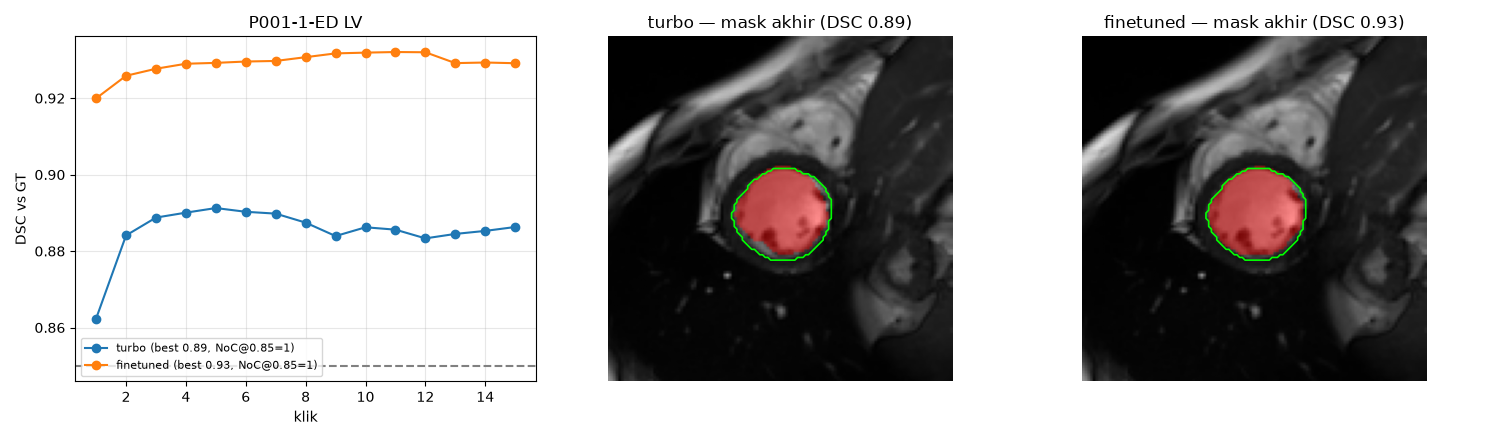

In [ ]:
STEM = sorted(df.stem)[0]   # ganti kasus di sini
CLS  = 1                     # 1=LV, 2=MYO, 3=RV

@torch.no_grad()
def run_oracle(roi_model, gt, maxc=MAX_CLICKS):
    emb=encode_fn(roi_model); pts=[]; labs=[]; prev=None; pb=np.zeros((SAM_ROI,)*3,bool); curve=[]; masks={}
    for k in range(1,maxc+1):
        c,l=next_click(pb,gt)
        if c is None: break
        pts.append(c); labs.append(l); pb,prev=decode_fn(emb,pts,labs,prev)
        curve.append(dsc(pb,gt))
        if k in (1,5,maxc): masks[k]=pb.copy()
    return curve, pb

def noc_at(curve,thr):
    for i,d in enumerate(curve,1):
        if d>=thr: return i
    return None

r=build_case_demo(STEM,CLS)
assert r is not None, "GT kosong untuk kombinasi ini"
model_roi,disp,gt,ctr,sa=r
res={}
for src in ("turbo","finetuned"):
    set_model(src, fold_of[STEM]); res[src]=run_oracle(model_roi,gt)

fig,ax=plt.subplots(1,3,figsize=(15,4.4))
for src,c in [("turbo","C0"),("finetuned","C1")]:
    cur=res[src][0]; ax[0].plot(range(1,len(cur)+1),cur,marker="o",color=c,
        label=f"{src} (best {max(cur):.2f}, NoC@0.85={noc_at(cur,0.85)})")
ax[0].axhline(0.85,ls="--",c="gray"); ax[0].set_xlabel("klik"); ax[0].set_ylabel("DSC vs GT")
ax[0].set_title(f"{STEM} {FOCUS[CLS]}"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
z=ctr[sa]
for a,src in zip(ax[1:],("turbo","finetuned")):
    a.imshow(np.take(disp,z,axis=sa),cmap="gray")
    pm=np.take(res[src][1],z,axis=sa)
    if pm.any(): a.imshow(np.ma.masked_where(~pm,pm),cmap="autumn",alpha=.45)
    g=np.take(gt,z,axis=sa)
    if g.any(): a.contour(g,levels=[0.5],colors="lime",linewidths=1.2)
    a.set_title(f"{src} — mask akhir (DSC {res[src][0][-1]:.2f})"); a.axis("off")
plt.tight_layout(); plt.savefig(RESULT_DIR/f"diag_{STEM}_{FOCUS[CLS]}.png",dpi=150); plt.show()

## 5b. Perbandingan zero-shot vs fine-tuned — grid 3×2 (satu figur, render)

Grid satu figur: baris = LV / MYO / RV, kolom = zero-shot (Turbo) vs fine-tuned.
Snapshot pada budget klik yang sama (`NCLICKS_GRID`), klik oracle identik (fungsi `next_click` yang sama),
slice short-axis tengah GT. **Render via `savefig` (bukan screenshot UI)** untuk langsung dipakai di skripsi.


tersimpan: D:\Joel\work\results_noc\grid_P001-1-ED_zs_vs_ft_5klik.png
Gambar — Perbandingan zero-shot (Turbo) vs fine-tuned pada kasus P001-1-ED (fold 0). Baris: LV, MYO, RV; kolom: zero-shot vs fine-tuned. Setiap panel: overlay mask prediksi (oranye) dan kontur GT (hijau) pada slice short-axis tengah GT dengan budget 5 klik oracle yang identik. Angka DSC@N tercantum per panel.
LV: ZS DSC@5=0.891 (NoC@0.85=1) | FT DSC@5=0.929 (NoC@0.85=1)
MYO: ZS DSC@5=0.081 (NoC@0.85=None) | FT DSC@5=0.811 (NoC@0.85=None)
RV: ZS DSC@5=0.839 (NoC@0.85=None) | FT DSC@5=0.901 (NoC@0.85=2)
model dikembalikan ke demo: turbo / P001-1-ED (silakan tekan Muat di Section 4 untuk re-encode bersih)


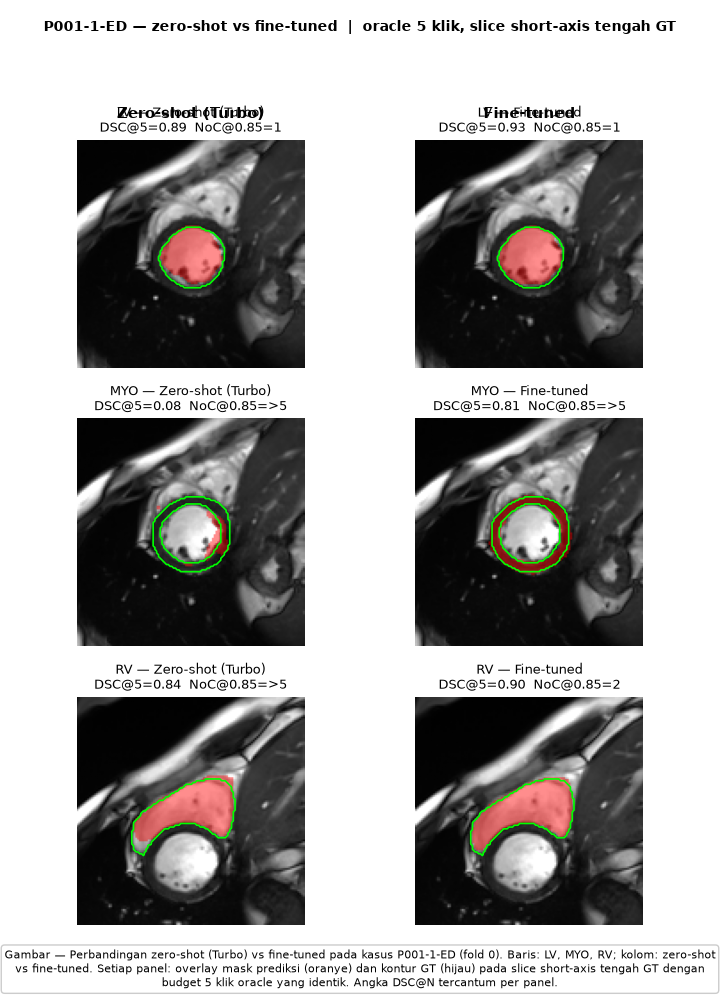

In [ ]:
STEM_GRID = sorted(df.stem)[0]  # <-- ganti kasus di sini
NCLICKS_GRID = 5  # budget klik oracle yang SAMA untuk semua panel (banding apel-vs-apel)

import numpy as np
import matplotlib.pyplot as plt
import torch

# --- fungsi mandiri (tidak tergantung sel 5, aman di-run ulang) ---
@torch.no_grad()
def _run_oracle_grid(roi_model, gt, maxc):
    emb = encode_fn(roi_model)
    pts, labs, prev = [], [], None
    pb = np.zeros((SAM_ROI,)*3, bool)
    curve = []
    for k in range(1, maxc+1):
        c, l = next_click(pb, gt)
        if c is None:
            break
        pts.append(c); labs.append(l)
        pb, prev = decode_fn(emb, pts, labs, prev)
        curve.append(dsc(pb, gt))
    return curve, pb

def _noc_at(curve, thr=0.85):
    for i, d in enumerate(curve, 1):
        if d >= thr:
            return i
    return None

# --- simpan model global agar demo Section 4 tidak terkontaminasi ---
_sam_before = sam  # objek model aktif sebelum grid (None bila belum load)

STRUCTS = [(1, "LV"), (2, "MYO"), (3, "RV")]
COLS = [("turbo", "Zero-shot (Turbo)"), ("finetuned", "Fine-tuned")]
fold = fold_of[STEM_GRID]

# --- kumpulkan hasil: 3 struktur x 2 model = 6 run oracle ---
grid = {}  # (cls, src) -> dict
for cls, cname in STRUCTS:
    r = build_case_demo(STEM_GRID, cls)
    if r is None:
        for src, _ in COLS:
            grid[(cls, src)] = None
        print(f"{cname}: GT kosong, panel dikosongkan")
        continue
    model_roi, disp, gt, ctr, sa = r
    z = int(ctr[sa])
    vmin, vmax = float(np.percentile(disp, 1)), float(np.percentile(disp, 99))
    for src, _ in COLS:
        set_model(src, fold)  # ganti bobot encoder/decoder per kolom
        curve, pred = _run_oracle_grid(model_roi, gt, NCLICKS_GRID)
        final = float(curve[-1]) if curve else 0.0
        grid[(cls, src)] = dict(disp=np.take(disp, z, axis=sa),
                                gt=np.take(gt, z, axis=sa),
                                pred=np.take(pred, z, axis=sa),
                                curve=curve, dsc=final,
                                noc=_noc_at(curve), z=z, vmin=vmin, vmax=vmax)

# --- render SATU figur 3x2 ---
fig, axes = plt.subplots(3, 2, figsize=(7.2, 10))
fig.suptitle(f"{STEM_GRID} \u2014 zero-shot vs fine-tuned  |  oracle {NCLICKS_GRID} klik, slice short-axis tengah GT",
             fontsize=10, fontweight="bold", y=0.98)

for i, (cls, cname) in enumerate(STRUCTS):
    for j, (src, ctitle) in enumerate(COLS):
        ax = axes[i, j]
        res = grid[(cls, src)]
        if res is None:
            ax.text(0.5, 0.5, "GT kosong", ha="center", va="center", fontsize=10)
            ax.axis("off")
            continue
        ax.imshow(res["disp"], cmap="gray", vmin=res["vmin"], vmax=res["vmax"])
        if res["pred"].any():
            ax.imshow(np.ma.masked_where(~res["pred"], res["pred"]),
                      cmap="autumn", alpha=0.45)
        if res["gt"].any():
            ax.contour(res["gt"], levels=[0.5], colors="lime", linewidths=1.2)
        noc_txt = res["noc"] if res["noc"] is not None else f">{NCLICKS_GRID}"
        ax.set_title(f"{cname} \u2014 {ctitle}\nDSC@{NCLICKS_GRID}={res['dsc']:.2f}  NoC@0.85={noc_txt}",
                     fontsize=9)
        ax.axis("off")
        if i == 0:
            ax.text(0.5, 1.08, ctitle, transform=ax.transAxes,
                    ha="center", va="bottom", fontsize=11, fontweight="bold")
        if j == 0:
            ax.set_ylabel(cname, fontsize=12, fontweight="bold", rotation=0,
                          ha="right", va="center", labelpad=20)

caption = (f"Gambar \u2014 Perbandingan zero-shot (Turbo) vs fine-tuned pada kasus {STEM_GRID} "
           f"(fold {fold}). Baris: LV, MYO, RV; kolom: zero-shot vs fine-tuned. "
           f"Setiap panel: overlay mask prediksi (oranye) dan kontur GT (hijau) pada slice short-axis "
           f"tengah GT dengan budget {NCLICKS_GRID} klik oracle yang identik. "
           f"Angka DSC@N tercantum per panel.")
fig.text(0.5, 0.01, caption, ha="center", va="bottom", fontsize=8, wrap=True,
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.8"))

plt.tight_layout(rect=[0, 0.06, 1, 0.94])
out = RESULT_DIR / f"grid_{STEM_GRID}_zs_vs_ft_{NCLICKS_GRID}klik.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
print(f"tersimpan: {out}")
print(caption)
# tabel ringkas untuk narasi skripsi
for cls, cname in STRUCTS:
    zt = grid[(cls, 'turbo')]; ft = grid[(cls, 'finetuned')]
    if zt and ft:
        print(f"{cname}: ZS DSC@{NCLICKS_GRID}={zt['dsc']:.3f} (NoC@0.85={zt['noc']}) | "
              f"FT DSC@{NCLICKS_GRID}={ft['dsc']:.3f} (NoC@0.85={ft['noc']})")
# --- kembalikan model global ke semula (penting! tanpa ini demo Section 4 jadi chimera) ---
sam = _sam_before
try:
    _demo_src = demo.dd_model.value
    _demo_stem = demo.dd_case.value
    set_model(_demo_src, fold_of[_demo_stem])
    print(f"model dikembalikan ke demo: {_demo_src} / {_demo_stem} (silakan tekan Muat di Section 4 untuk re-encode bersih)")
except Exception as e:
    print(f"model global dikembalikan ke objek semula ({type(sam).__name__}); tekan Muat di Section 4 sebelum klik lanjut. info: {e}")
plt.show()


## 6. (Opsional) Diagnostik agregat pada subjek test 1 fold

Lebih lambat (inferensi beberapa volume), tapi memberi angka rata-rata turbo vs
fine-tuned untuk dibawa ke dosbing. Pilih fold kecil dulu.

In [ ]:
RUN_AGG = False   # set True bila mau; makan waktu beberapa menit
AGG_FOLD = 0

if RUN_AGG:
    sub=df[df.fold==AGG_FOLD]
    rows=[]
    for src in ("turbo","finetuned"):
        set_model(src, AGG_FOLD)
        for row in sub.itertuples():
            for cls,cn in FOCUS.items():
                r=build_case_demo(row.stem,cls)
                if r is None: continue
                cur,_=run_oracle(r[0],r[2])
                rows.append({"model":src,"structure":cn,"best_dsc":max(cur),
                             "noc85":noc_at(cur,0.85),"reach85":max(cur)>=0.85})
    agg=pd.DataFrame(rows)
    print(agg.groupby(["model","structure"]).agg(
        reach85=("reach85","mean"), best_dsc=("best_dsc","median"),
        noc85_med=("noc85", lambda s: s.dropna().median())).round(3).to_string())
    agg.to_csv(RESULT_DIR/f"diag_agg_fold{AGG_FOLD}.csv",index=False)
else:
    print("RUN_AGG=False")

## 7. Kurva DSC-vs-klik + garis nnU-Net & reach/NoC@0.85 (render dari disk)

Bacaan cepat untuk dosbing, tanpa inferensi ulang (GPU tidak dipakai):
- Kiri: median DSC-vs-klik per struktur — FT frozen vs ZS turbo, garis putus-putus = median nnU-Net.
- Kanan/bawah: bar `reach@0.85` (proporsi kasus tembus) + boxplot sebaran `NoC@0.85` pada kasus yang tembus.
Sumber: `noc_curves_gt_frozen.csv` (FT), `noc_curves_gt_zeroshot.csv` (ZS, hanya LV/RV), `nnunet_dsc_perkasus.csv`. Catatan: ZS-MYO memang tidak dievaluasi (`n/a`).


FT: 6210 baris | ZS: 4140 baris | nnU-Net: 414 baris
tersimpan: D:\Joel\work\results_noc\kurva_dsc_klik_dgn_nnunet.png


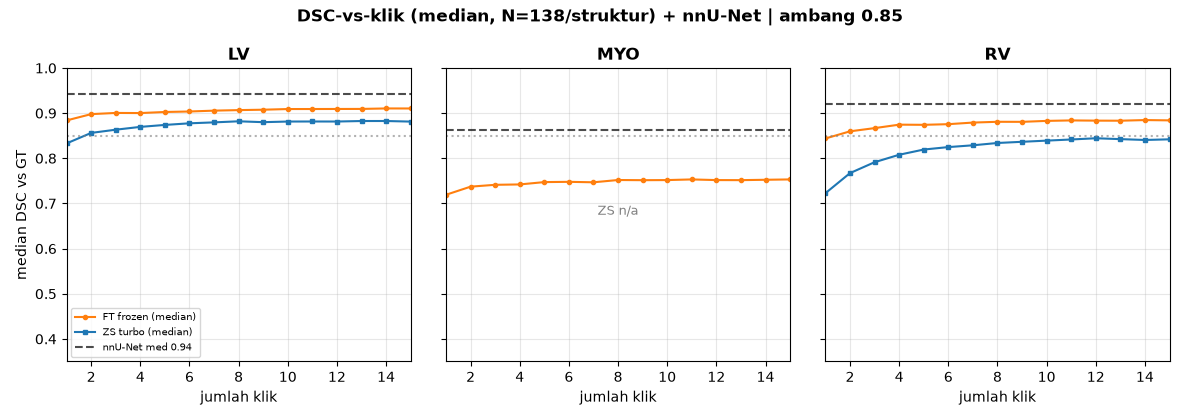

tersimpan: D:\Joel\work\results_noc\bar_reach_box_noc_0p85.png


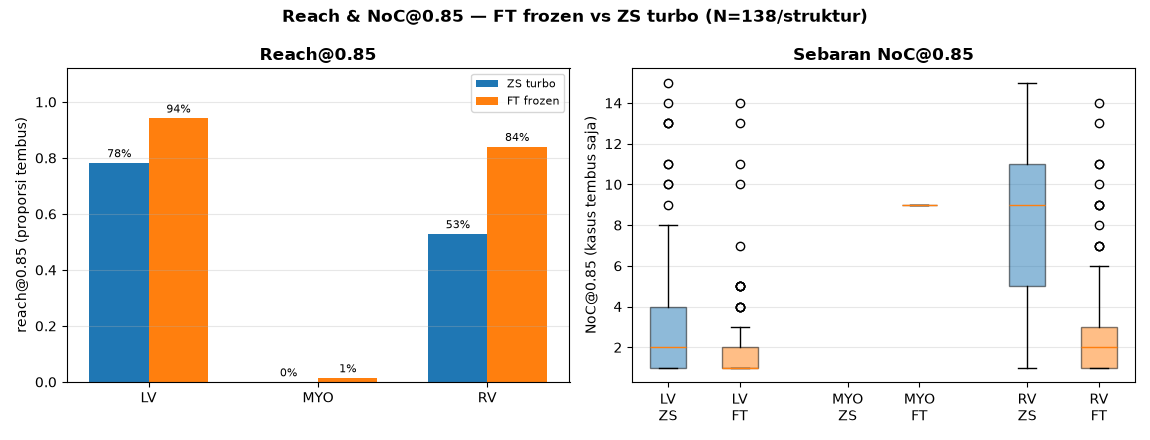


== headline @0.85 ==
LV: reach ZS=0.783 FT=0.942 | NoCmed ZS=2.0 FT=1.0 | nnU-Net med=0.941
MYO: reach ZS=nan FT=0.014 | NoCmed ZS=nan FT=9.0 | nnU-Net med=0.863
RV: reach ZS=0.529 FT=0.841 | NoCmed ZS=9.0 FT=2.0 | nnU-Net med=0.920


In [ ]:
THR = 0.85  # ambang reach/NoC (samakan dengan headline)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

f_ft, f_zs, f_nn = RESULT_DIR/"noc_curves_gt_frozen.csv", RESULT_DIR/"noc_curves_gt_zeroshot.csv", RESULT_DIR/"nnunet_dsc_perkasus.csv"
assert f_ft.exists() and f_nn.exists(), f"file hilang: {f_ft} / {f_nn}"
ft = pd.read_csv(f_ft); nn = pd.read_csv(f_nn)
zs = pd.read_csv(f_zs) if f_zs.exists() else pd.DataFrame(columns=ft.columns)
print(f"FT: {len(ft)} baris | ZS: {len(zs)} baris | nnU-Net: {len(nn)} baris")
if len(zs) == 0: print("peringatan: kurva ZS tak ada/kosong — panel ZS dikosongkan")

def noc_per_case(curves, thr):
    recs = []
    for (stem, struct), sub in curves.sort_values("click").groupby(["stem", "structure"]):
        sub = sub.sort_values("click"); hit = sub[sub.dsc >= thr]
        recs.append({"stem": stem, "structure": struct,
                     "noc": float(hit.click.iloc[0]) if len(hit) else np.nan,
                     "reach": bool(len(hit))})
    return pd.DataFrame(recs)

med_ft = ft.groupby(["structure", "click"]).dsc.median().reset_index()
med_zs = zs.groupby(["structure", "click"]).dsc.median().reset_index() if len(zs) else pd.DataFrame(columns=["structure","click","dsc"])
nn_med = nn.groupby("structure").nnunet_dsc_iso.median()
noc_ft, noc_zs = noc_per_case(ft, THR), noc_per_case(zs, THR) if len(zs) else pd.DataFrame(columns=["stem","structure","noc","reach"])
STRUCTS = ["LV", "MYO", "RV"]

# ---------- Fig A: kurva DSC-vs-klik + garis nnU-Net ----------
figA, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for ax, s in zip(axes, STRUCTS):
    f = med_ft[med_ft.structure == s]
    ax.plot(f.click, f.dsc, marker="o", ms=3, color="C1", label="FT frozen (median)")
    z = med_zs[med_zs.structure == s] if len(med_zs) else pd.DataFrame()
    if len(z): ax.plot(z.click, z.dsc, marker="s", ms=3, color="C0", label="ZS turbo (median)")
    else: ax.text(0.5, 0.5, "ZS n/a", transform=ax.transAxes, ha="center", fontsize=9, color="gray")
    if s in nn_med.index: ax.axhline(float(nn_med[s]), ls="--", color="k", alpha=0.7, label=f"nnU-Net med {float(nn_med[s]):.2f}")
    ax.axhline(THR, ls=":", color="gray", alpha=0.6)
    ax.set_title(s, fontweight="bold"); ax.set_xlabel("jumlah klik"); ax.grid(alpha=0.3); ax.set_ylim(0.35, 1.0); ax.set_xlim(1, 15)
axes[0].set_ylabel("median DSC vs GT")
axes[0].legend(fontsize=7)
figA.suptitle(f"DSC-vs-klik (median, N=138/struktur) + nnU-Net | ambang {THR}", fontweight="bold")
capA = (f"Gambar \u2014 Median DSC terhadap GT per jumlah klik. FT frozen vs ZS turbo; garis putus-putus hitam = median nnU-Net "
        f"(LV {float(nn_med.get('LV', float('nan'))):.2f} / MYO {float(nn_med.get('MYO', float('nan'))):.2f} / RV {float(nn_med.get('RV', float('nan'))):.2f}). "
        f"Garis titik-titik abu = ambang {THR}. ZS-MYO tidak dievaluasi.")
figA.text(0.5, -0.02, capA, ha="center", va="top", fontsize=8, wrap=True,
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.8"))
plt.tight_layout()
outA = RESULT_DIR/"kurva_dsc_klik_dgn_nnunet.png"
figA.savefig(outA, dpi=300, bbox_inches="tight")
print(f"tersimpan: {outA}")
plt.show()

# ---------- Fig B: bar reach@THR + boxplot NoC ----------
figB, (b1, b2) = plt.subplots(1, 2, figsize=(11.5, 4.4))
x = np.arange(len(STRUCTS)); w = 0.35
reach_ft = [float(noc_ft[noc_ft.structure == s].reach.mean()) if (noc_ft.structure == s).any() else 0.0 for s in STRUCTS]
reach_zs = [float(noc_zs[noc_zs.structure == s].reach.mean()) if len(noc_zs) and (noc_zs.structure == s).any() else 0.0 for s in STRUCTS]
b1.bar(x - w/2, reach_zs, w, color="C0", label="ZS turbo")
b1.bar(x + w/2, reach_ft, w, color="C1", label="FT frozen")
for i, (rz, rf) in enumerate(zip(reach_zs, reach_ft)):
    b1.text(i - w/2, rz + 0.02, f"{rz:.0%}", ha="center", fontsize=8)
    b1.text(i + w/2, rf + 0.02, f"{rf:.0%}", ha="center", fontsize=8)
b1.set_xticks(x); b1.set_xticklabels(STRUCTS); b1.set_ylabel(f"reach@{THR} (proporsi tembus)")
b1.set_ylim(0, 1.12); b1.legend(fontsize=8); b1.grid(axis="y", alpha=0.3); b1.set_title(f"Reach@{THR}", fontweight="bold")

data, pos, lbls, p = [], [], [], 1
for s in STRUCTS:
    for tag, ndf, col in [("ZS", noc_zs, "C0"), ("FT", noc_ft, "C1")]:
        v = ndf[(ndf.structure == s) & (ndf.reach)].noc.values if len(ndf) else np.array([])
        data.append(v if len(v) else np.array([np.nan])); pos.append(p); lbls.append(f"{s}\n{tag}"); p += 1
    p += 0.5
bp = b2.boxplot(data, positions=pos, tick_labels=lbls, patch_artist=True)
for patch, (s, tag) in zip(bp["boxes"], [(s, t) for s in STRUCTS for t in ("ZS", "FT")]):
    patch.set_facecolor("C0" if tag == "ZS" else "C1"); patch.set_alpha(0.5)
b2.set_ylabel(f"NoC@{THR} (kasus tembus saja)"); b2.grid(axis="y", alpha=0.3); b2.set_title(f"Sebaran NoC@{THR}", fontweight="bold")
figB.suptitle(f"Reach & NoC@{THR} — FT frozen vs ZS turbo (N=138/struktur)", fontweight="bold")
capB = (f"Gambar \u2014 Kiri: reach@{THR} (makin tinggi makin baik). Kanan: boxplot NoC@{THR} hanya pada kasus yang tembus "
        f"(makin rendah makin baik; n tembus per box berbeda — lihat Tabel). ZS-MYO n/a.")
figB.text(0.5, -0.02, capB, ha="center", va="top", fontsize=8, wrap=True,
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.8"))
plt.tight_layout()
outB = RESULT_DIR/f"bar_reach_box_noc_{str(THR).replace('.', 'p')}.png"
figB.savefig(outB, dpi=300, bbox_inches="tight")
print(f"tersimpan: {outB}")
plt.show()

# ---------- headline untuk narasi ----------
print(f"\n== headline @{THR} ==")
for s in STRUCTS:
    rf = float(noc_ft[noc_ft.structure == s].reach.mean()); rz = float(noc_zs[noc_zs.structure == s].reach.mean()) if len(noc_zs) and (noc_zs.structure == s).any() else float("nan")
    mf = noc_ft[(noc_ft.structure == s) & noc_ft.reach].noc.median(); mz = noc_zs[(noc_zs.structure == s) & noc_zs.reach].noc.median() if len(noc_zs) else float("nan")
    print(f"{s}: reach ZS={rz:.3f} FT={rf:.3f} | NoCmed ZS={mz} FT={mf} | nnU-Net med={float(nn_med.get(s, float('nan'))):.3f}")


## 8. Pasangan raw vs full-segmentasi per struktur (3 PNG terpisah)

Untuk tiap struktur (LV / MYO / RV) satu figur 1×2: kiri = dataset asli (grayscale, tanpa overlay), kanan = full tersegmentasi (overlay mask + kontur GT). File terpisah per struktur, tinggal download.
`USE_PRED=True` = mask kanan dari prediksi FT @N klik oracle; `False` = mask kanan = GT saja (tanpa inferensi).


tersimpan [LV]: D:\Joel\work\results_noc\pair_P001-1-ED_LV_raw_vs_seg.png


D:\Joel\work\results_noc\pair_P001-1-ED_LV_raw_vs_seg.png

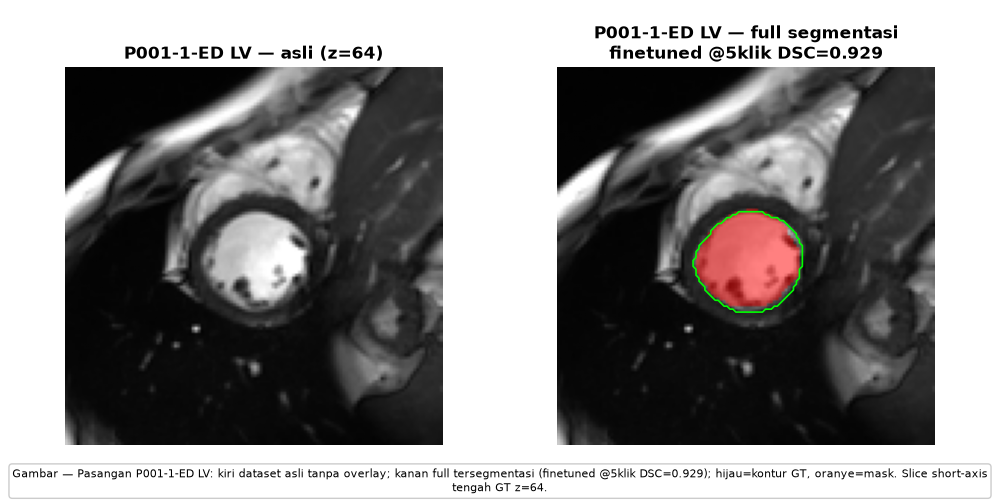

tersimpan [MYO]: D:\Joel\work\results_noc\pair_P001-1-ED_MYO_raw_vs_seg.png


D:\Joel\work\results_noc\pair_P001-1-ED_MYO_raw_vs_seg.png

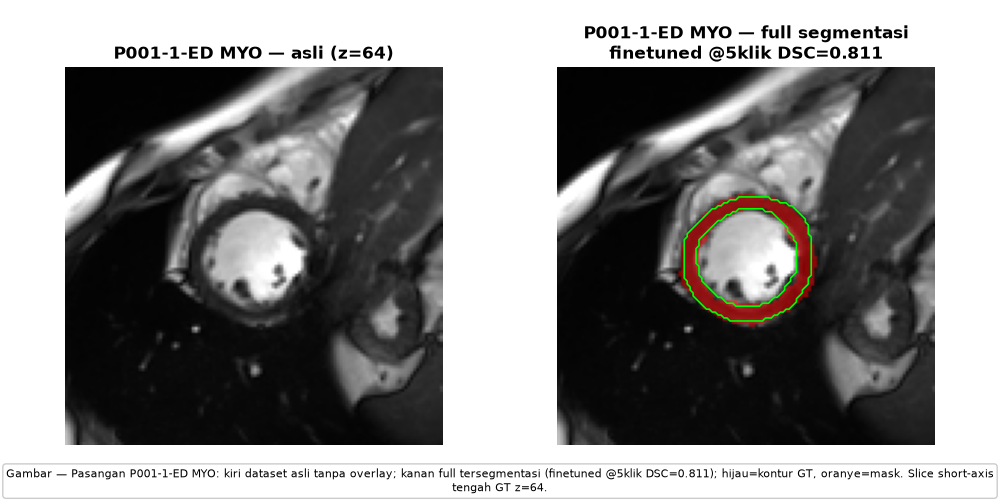

tersimpan [RV]: D:\Joel\work\results_noc\pair_P001-1-ED_RV_raw_vs_seg.png


D:\Joel\work\results_noc\pair_P001-1-ED_RV_raw_vs_seg.png

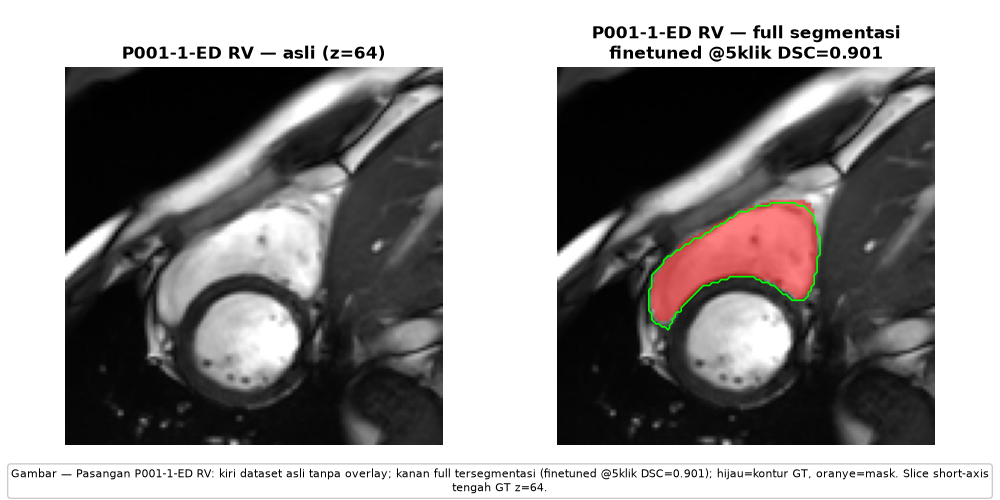


Selesai: 3 file: D:\Joel\work\results_noc\pair_P001-1-ED_LV_raw_vs_seg.png, D:\Joel\work\results_noc\pair_P001-1-ED_MYO_raw_vs_seg.png, D:\Joel\work\results_noc\pair_P001-1-ED_RV_raw_vs_seg.png


In [ ]:
STEM_PAIR = sorted(df.stem)[0]  # <-- ganti kasus di sini
NCLICKS_PAIR = 5       # budget oracle bila USE_PRED=True
MODEL_SRC = "finetuned"  # "finetuned" atau "turbo" bila USE_PRED=True
USE_PRED = True        # False = kanan cukup GT (cepat, tanpa GPU)

import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display, FileLink

def _pair_pred(roi_model, gt, src, fold, nclicks):
    """kembalikan (pred, curve); pakai jalur eksplisit bila sel 4b sudah di-run, else fallback global."""
    if "_encode_with" in globals() and "_decode_with" in globals() and "_get_model_obj" in globals():
        mod = _get_model_obj(src, fold)
        emb = _encode_with(mod, roi_model)
        pts, labs, prev, pb, curve = [], [], None, np.zeros((SAM_ROI,)*3, bool), []
        with torch.no_grad():
            for k in range(1, nclicks+1):
                c, l = next_click(pb, gt)
                if c is None: break
                pts.append(c); labs.append(l)
                pb, prev = _decode_with(mod, emb, pts, labs, prev)
                curve.append(dsc(pb, gt))
        return pb, curve
    else:
        set_model(src, fold)
        with torch.no_grad():
            emb = encode_fn(roi_model)
            pts, labs, prev, pb, curve = [], [], None, np.zeros((SAM_ROI,)*3, bool), []
            for k in range(1, nclicks+1):
                c, l = next_click(pb, gt)
                if c is None: break
                pts.append(c); labs.append(l)
                pb, prev = decode_fn(emb, pts, labs, prev)
                curve.append(dsc(pb, gt))
        return pb, curve

STRUCTS_PAIR = [(1, "LV"), (2, "MYO"), (3, "RV")]
fold_pair = fold_of[STEM_PAIR]
saved = []
for cls, cname in STRUCTS_PAIR:
    r = build_case_demo(STEM_PAIR, cls)
    if r is None:
        print(f"{cname}: GT kosong, dilewati"); continue
    model_roi, disp, gt, ctr, sa = r
    z = int(ctr[sa])
    vmin, vmax = float(np.percentile(disp, 1)), float(np.percentile(disp, 99))
    img = np.take(disp, z, axis=sa); g = np.take(gt, z, axis=sa)
    if USE_PRED:
        pred_vol, curve = _pair_pred(model_roi, gt, MODEL_SRC, fold_pair, NCLICKS_PAIR)
        mask = np.take(pred_vol, z, axis=sa); tag = f"{MODEL_SRC} @{len(curve)}klik DSC={curve[-1]:.3f}" if curve else f"{MODEL_SRC} (kosong)"
    else:
        mask = g; tag = "GT penuh"
    fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 5))
    a0.imshow(img, cmap="gray", vmin=vmin, vmax=vmax); a0.set_title(f"{STEM_PAIR} {cname} \u2014 asli (z={z})", fontweight="bold"); a0.axis("off")
    a1.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    if mask.any(): a1.imshow(np.ma.masked_where(~mask, mask), cmap="autumn", alpha=0.5)
    if g.any(): a1.contour(g, levels=[0.5], colors="lime", linewidths=1.2)
    a1.set_title(f"{STEM_PAIR} {cname} \u2014 full segmentasi\n{tag}", fontweight="bold"); a1.axis("off")
    cap = (f"Gambar \u2014 Pasangan {STEM_PAIR} {cname}: kiri dataset asli tanpa overlay; kanan full tersegmentasi ({tag}); "
           f"hijau=kontur GT, oranye=mask. Slice short-axis tengah GT z={z}.")
    fig.text(0.5, 0.01, cap, ha="center", va="bottom", fontsize=8, wrap=True,
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.8"))
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    out = RESULT_DIR / f"pair_{STEM_PAIR}_{cname}_raw_vs_seg.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    saved.append(str(out))
    print(f"tersimpan [{cname}]: {out}")
    try: display(FileLink(str(out)))
    except Exception as e: print(e)
    plt.show()
print(f"\nSelesai: {len(saved)} file: " + ", ".join(saved))


## 9. Pasangan native per struktur — asli vs GT asli (tanpa crop/resample)

Murni dari folder dataset (`*-label.nii.gz`), tanpa `resample_iso`, tanpa `crop_center`, tanpa znorm. Tiap struktur satu figur 1×2 (kiri = citra asli, kanan = citra + mask GT + kontur), 3 file PNG terpisah. Slice = tengah rentang GT struktur itu di sumbu short-axis native.


P001-1-ED: shape=(480, 512, 11) spacing=(0.672, 0.672, 10.0) slice-axis=2
label unik: [0.0, 1.0, 2.0, 3.0]
tersimpan [LV] slice 6: D:\Joel\work\results_noc\native_pair_P001-1-ED_LV_raw_vs_GT.png (piksel GT di slice: 4158)


D:\Joel\work\results_noc\native_pair_P001-1-ED_LV_raw_vs_GT.png

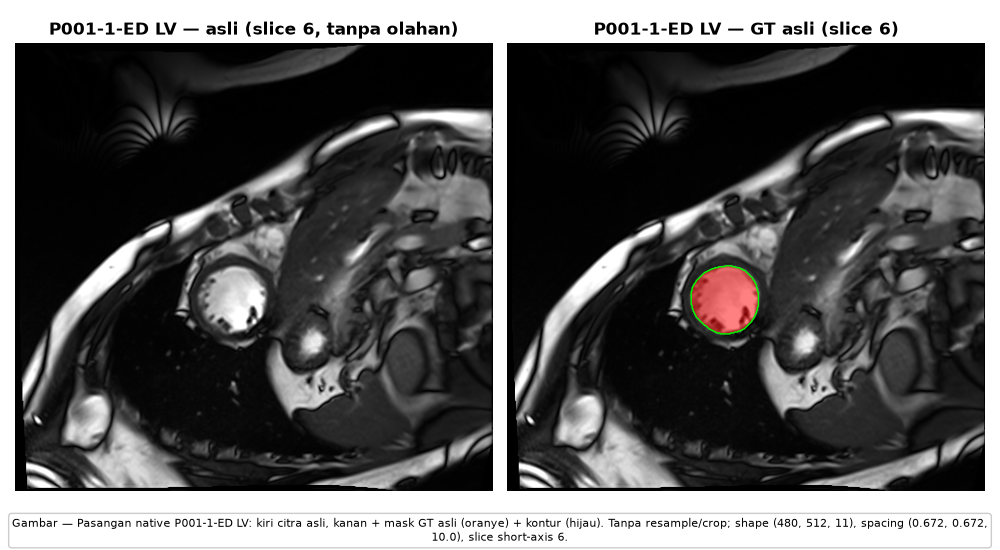

tersimpan [MYO] slice 6: D:\Joel\work\results_noc\native_pair_P001-1-ED_MYO_raw_vs_GT.png (piksel GT di slice: 2558)


D:\Joel\work\results_noc\native_pair_P001-1-ED_MYO_raw_vs_GT.png

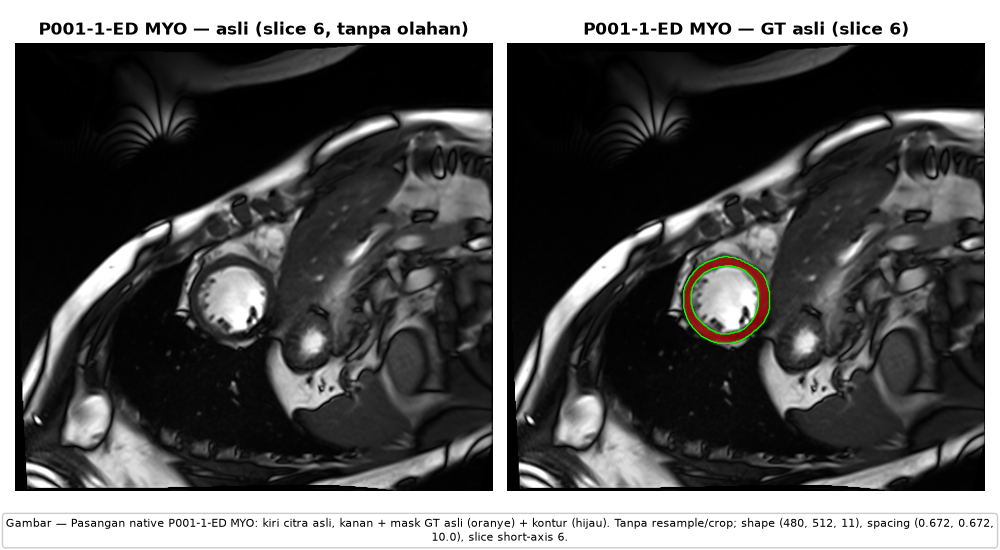

tersimpan [RV] slice 5: D:\Joel\work\results_noc\native_pair_P001-1-ED_RV_raw_vs_GT.png (piksel GT di slice: 4241)


D:\Joel\work\results_noc\native_pair_P001-1-ED_RV_raw_vs_GT.png

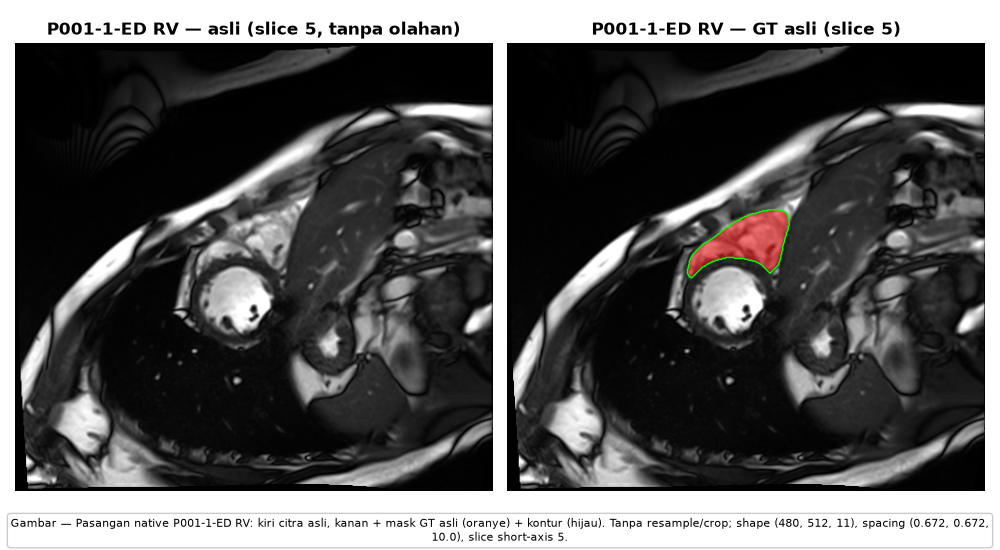


Selesai: 3 file: D:\Joel\work\results_noc\native_pair_P001-1-ED_LV_raw_vs_GT.png, D:\Joel\work\results_noc\native_pair_P001-1-ED_MYO_raw_vs_GT.png, D:\Joel\work\results_noc\native_pair_P001-1-ED_RV_raw_vs_GT.png


In [ ]:
STEM_NATIVE = sorted(df.stem)[0]  # <-- ganti kasus di sini

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

row = df[df.stem == STEM_NATIVE].iloc[0]
img_nat = load_vol(row.image)   # native: hanya squeeze 4D, TANPA resample/crop
lab_nat = load_vol(row.label)   # nilai 1=LV, 2=MYO, 3=RV
sp_nat = native_spacing(row.image)
sa_nat = int(np.argmax(sp_nat))  # sumbu short-axis native (spacing terbesar)
print(f"{STEM_NATIVE}: shape={img_nat.shape} spacing={tuple(round(float(s),3) for s in sp_nat)} slice-axis={sa_nat}")
print(f"label unik: {sorted(np.unique(lab_nat).tolist())}")

saved_nat = []
for cls, cname in [(1, "LV"), (2, "MYO"), (3, "RV")]:
    m = (lab_nat == cls)
    if not m.any():
        print(f"{cname}: GT kosong di file asli, dilewati"); continue
    other = tuple(a for a in range(3) if a != sa_nat)
    has = np.where(m.any(axis=other))[0]
    z = int(has[len(has)//2])
    sl = np.take(img_nat, z, axis=sa_nat); g = np.take(m, z, axis=sa_nat)
    vmin, vmax = float(np.percentile(sl, 1)), float(np.percentile(sl, 99))
    fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 5.5))
    a0.imshow(sl, cmap="gray", vmin=vmin, vmax=vmax)
    a0.set_title(f"{STEM_NATIVE} {cname} \u2014 asli (slice {z}, tanpa olahan)", fontweight="bold"); a0.axis("off")
    a1.imshow(sl, cmap="gray", vmin=vmin, vmax=vmax)
    if g.any():
        a1.imshow(np.ma.masked_where(~g, g), cmap="autumn", alpha=0.5)
        a1.contour(g, levels=[0.5], colors="lime", linewidths=1.0)
    a1.set_title(f"{STEM_NATIVE} {cname} \u2014 GT asli (slice {z})", fontweight="bold"); a1.axis("off")
    cap = (f"Gambar \u2014 Pasangan native {STEM_NATIVE} {cname}: kiri citra asli, kanan + mask GT asli (oranye) + kontur (hijau). "
           f"Tanpa resample/crop; shape {img_nat.shape}, spacing {tuple(round(float(s),3) for s in sp_nat)}, slice short-axis {z}.")
    fig.text(0.5, 0.01, cap, ha="center", va="bottom", fontsize=8, wrap=True,
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.8"))
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    out = RESULT_DIR / f"native_pair_{STEM_NATIVE}_{cname}_raw_vs_GT.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    saved_nat.append(str(out))
    print(f"tersimpan [{cname}] slice {z}: {out} (piksel GT di slice: {int(g.sum())})")
    try: display(FileLink(str(out)))
    except Exception as e: print(e)
    plt.show()
print(f"\nSelesai: {len(saved_nat)} file: " + ", ".join(saved_nat))
